In [12]:
import numpy as np
import json
import cv2
import matplotlib.pyplot as plt

from copy import deepcopy
from scipy.optimize import minimize
from pathlib import Path

In [13]:
# Paths
experiment_name = 'mustard_bottle_arucos'
path_before = Path(f'../data/real/remove/single/{experiment_name}/{experiment_name}/before')
path_after = Path(f'../data/real/remove/single/{experiment_name}/{experiment_name}/after')

In [14]:
# Load transformation
with open(path_before / 'transforms.json', 'r') as file:
    transforms_before = json.load(file)

with open(path_after / 'transforms.json', 'r') as file:
    transforms_after = json.load(file)

print(len(transforms_before["frames"]), len(transforms_after["frames"]))

282 279


In [15]:
# Sort frames
transforms_before["frames"] = sorted(transforms_before["frames"], key=lambda x: x["file_path"])
transforms_after["frames"] = sorted(transforms_after["frames"], key=lambda x: x["file_path"])

In [16]:
# Calculate distance between frames
distances_before = []
for i in range(len(transforms_before["frames"]) - 1):
    first = np.array(transforms_before["frames"][i]["transform_matrix"])[:3, 3]
    second = np.array(transforms_before["frames"][i + 1]["transform_matrix"])[:3, 3]
    distances_before.append(np.linalg.norm(second - first))

distances_after = []
for i in range(len(transforms_after["frames"]) - 1):
    first = np.array(transforms_after["frames"][i]["transform_matrix"])[:3, 3]
    second = np.array(transforms_after["frames"][i + 1]["transform_matrix"])[:3, 3]
    distances_after.append(np.linalg.norm(second - first))

print(len(distances_before), len(distances_after))
print(sum(distances_before), sum(distances_after))
print(max(distances_before), max(distances_after))
print(min(distances_before), min(distances_after))
print(distances_before)
print(distances_after)

281 278
7.5617168439591405 7.99056449419138
0.15430305707431952 0.16733563589725126
0.00011544259537006012 3.5362226237117254e-05
[0.000329658925454687, 0.00028844806803263504, 0.00011544259537006012, 0.00015820945972465787, 0.00021248033373531147, 0.000151707558051281, 0.00015958415845845035, 0.00018649982439915595, 0.09663427194543868, 0.05057134993566437, 0.04691897204026433, 0.043526272354384304, 0.041159947070362336, 0.0357942334259016, 0.03114148400937264, 0.02555569552000425, 0.02214920216874537, 0.01792404783539891, 0.015210603114548037, 0.012724329963305622, 0.010500571552845114, 0.009645265541825177, 0.007787747435811006, 0.006646304474177774, 0.010612240353935015, 0.15430305707431952, 0.13579897664880033, 0.11141391890272913, 0.09656012770291661, 0.08161486302559952, 0.07698938913357177, 0.06778402835089493, 0.05837931236145368, 0.05293162772797523, 0.04833529550643841, 0.0424219795637238, 0.03736279160268227, 0.03235550838725261, 0.03091310401902228, 0.02656166039529152, 0.

In [17]:
# Interpolate distances
def interpolate_distances(distances):
    interpolated = []
    for i in range(len(distances) - 1):
        interpolated.append(distances[i])
        interpolated.extend(np.linspace(distances[i], distances[i + 1], num=6, endpoint=False)[1:])
    interpolated.append(distances[-1])
    return interpolated

distances_before_inerpolated = interpolate_distances(distances_before)
distances_after_interpolated = interpolate_distances(distances_after)

print(len(distances_before_inerpolated), len(distances_after_interpolated))
print(distances_before_inerpolated)
print(distances_after_interpolated)

1681 1663
[0.000329658925454687, 0.00032279044921767835, 0.00031592197298066965, 0.000309053496743661, 0.0003021850205066524, 0.0002953165442696437, 0.00028844806803263504, 0.00025961382258887257, 0.00023077957714511007, 0.00020194533170134757, 0.0001731110862575851, 0.0001442768408138226, 0.00011544259537006012, 0.00012257040609582641, 0.0001296982168215927, 0.000136826027547359, 0.00014395383827312528, 0.0001510816489988916, 0.00015820945972465787, 0.00016725460539310013, 0.0001762997510615424, 0.00018534489672998467, 0.00019439004239842693, 0.0002034351880668692, 0.00021248033373531147, 0.00020235153778797306, 0.00019222274184063463, 0.00018209394589329623, 0.00017196514994595783, 0.00016183635399861943, 0.000151707558051281, 0.00015302032478580922, 0.00015433309152033744, 0.00015564585825486566, 0.0001569586249893939, 0.00015827139172392213, 0.00015958415845845035, 0.00016407010278190128, 0.00016855604710535222, 0.00017304199142880315, 0.00017752793575225408, 0.00018201388007570501

In [18]:
from scipy.optimize import minimize_scalar

# Reduce number of frames
num_frames = 250

def optimize_dist(dist, distances):
    selected_frames = []
    current_distance = 0

    for idx, distance in enumerate(distances):
        current_distance += distance
        if current_distance >= dist:
            selected_frames.append(idx)
            current_distance = 0

    return abs(len(selected_frames) - num_frames)

result = minimize_scalar(optimize_dist, args=(distances_before_inerpolated))
dist_before = result.x

# Recalculate selected_frames with optimized dist_before
selected_frames_before = []
current_distance = 0

for idx, distance in enumerate(distances_before_inerpolated):
    current_distance += distance
    if current_distance >= dist_before:
        selected_frames_before.append(idx)
        current_distance = 0

print(f"Optimized dist_before: {dist_before}")
print(f"Selected {len(selected_frames_before)} frames out of {len(distances_before_inerpolated)}")

result = minimize_scalar(optimize_dist, args=(distances_after_interpolated))
dist_after = result.x

# Recalculate selected_frames with optimized dist_after
selected_frames_after = []
current_distance = 0

for idx, distance in enumerate(distances_after_interpolated):
    current_distance += distance
    if current_distance >= dist_after:
        selected_frames_after.append(idx)
        current_distance = 0

print(f"Optimized dist_after: {dist_after}")
print(f"Selected {len(selected_frames_after)} frames out of {len(distances_after_interpolated)}")
print(selected_frames_before)
print(selected_frames_after)

Optimized dist_before: 0.1559574587949267
Selected 250 frames out of 1681
Optimized dist_after: 0.16482017655640266
Selected 249 frames out of 1663
[46, 48, 50, 53, 57, 61, 65, 69, 73, 78, 83, 89, 96, 105, 117, 134, 146, 148, 150, 152, 154, 156, 158, 160, 162, 164, 166, 168, 170, 172, 174, 176, 178, 181, 184, 187, 190, 193, 196, 199, 203, 207, 211, 215, 220, 225, 231, 237, 244, 253, 263, 278, 298, 328, 339, 342, 345, 348, 351, 354, 358, 362, 367, 373, 380, 389, 400, 417, 441, 450, 453, 455, 457, 459, 461, 463, 465, 467, 469, 471, 473, 475, 477, 479, 482, 485, 488, 491, 494, 497, 500, 503, 506, 509, 512, 516, 520, 524, 528, 532, 536, 541, 546, 551, 557, 563, 570, 577, 585, 594, 604, 615, 628, 644, 661, 688, 711, 715, 717, 719, 721, 723, 725, 727, 729, 731, 733, 735, 737, 739, 741, 743, 745, 747, 749, 751, 753, 756, 759, 762, 765, 768, 771, 774, 777, 780, 783, 786, 789, 793, 797, 802, 806, 811, 816, 821, 827, 834, 841, 849, 857, 865, 874, 884, 898, 915, 939, 969, 978, 985, 993, 1002, 101

In [7]:
# Selecnt new transforms
transforms_before["frames"] = list(np.array(transforms_before["frames"])[selected_frames_before])
transforms_after["frames"] = list(np.array(transforms_after["frames"])[selected_frames_after])

In [8]:
# Load images
images_before = []
for frame in transforms_before["frames"]:
    images_before.append(cv2.imread(str(path_before / frame["file_path"])))

images_after = []
for frame in transforms_after["frames"]:
    images_after.append(cv2.imread(str(path_after / frame["file_path"])))

In [9]:
def get_marker_pose(corners, camera_matrix, dist_coeffs):
    """ Compute the pose of a marker given its corners. """
    # Define the length of the marker's side (in meters or other units)
    marker_length = 0.1  # Adjust based on your marker size
    # Create an object point array (3D points in the marker's coordinate system)
    obj_points = np.array([
        [-marker_length / 2, marker_length / 2, 0],
        [marker_length / 2, marker_length / 2, 0],
        [marker_length / 2, -marker_length / 2, 0],
        [-marker_length / 2, -marker_length / 2, 0]
    ], dtype=np.float32)

    # Solve the PnP problem to get rotation and translation vectors
    _, rvec, tvec = cv2.solvePnP(obj_points, corners, camera_matrix, dist_coeffs, False, cv2.SOLVEPNP_IPPE_SQUARE)
    return rvec, tvec

In [10]:
# Define ArUco dictionary and parameters
dictionary = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_4X4_100)
parameters = cv2.aruco.DetectorParameters()
detector = cv2.aruco.ArucoDetector(dictionary, parameters)

In [11]:
# Define camera parameters for world before
camera_matrix = np.array([[transforms_before["fl_x"], 0, transforms_before["cx"]], 
                        [0, transforms_before["fl_y"], transforms_before["cy"]], 
                        [0, 0, 1]])
dist_coeffs = np.zeros((4, 1))

# Detect Aruco markers
arucos_before = []
for image, frame in zip(images_before, transforms_before["frames"]):
    corners, ids, _ = detector.detectMarkers(image)

    for i in range(len(corners)):
        # Compute poses
        rvec, tvec = get_marker_pose(corners[i], camera_matrix, dist_coeffs)

        R, _ = cv2.Rodrigues(rvec)
        
        trans = np.eye(4)
        trans[:3, :3] = R
        trans[:3, 3:] = tvec

        # Convert rotation vectors to matrices
        transform_matrix = np.array(frame["transform_matrix"])

        transform = np.array([[1, 0, 0, 0],
                              [0, -1, 0, 0],
                              [0, 0, -1, 0],
                              [0, 0, 0, 1]])

        marker_pose = (transform_matrix, transform @ trans, ids[i][0])
        
        arucos_before.append(marker_pose)

In [12]:
# Define camera parameters for world after
camera_matrix = np.array([[transforms_after["fl_x"], 0, transforms_after["cx"]], 
                        [0, transforms_after["fl_y"], transforms_after["cy"]], 
                        [0, 0, 1]])
dist_coeffs = np.zeros((4, 1))

# Detect Aruco markers
arucos_after = []
for image, frame in zip(images_after, transforms_after["frames"]):
    corners, ids, _ = detector.detectMarkers(image)

    for i in range(len(corners)):
        # Compute poses
        rvec, tvec = get_marker_pose(corners[i], camera_matrix, dist_coeffs)

        R, _ = cv2.Rodrigues(rvec)
        
        trans = np.eye(4)
        trans[:3, :3] = R
        trans[:3, 3:] = tvec

        # Convert rotation vectors to matrices
        transform_matrix = np.array(frame["transform_matrix"])

        transform = np.array([[1, 0, 0, 0],
                              [0, -1, 0, 0],
                              [0, 0, -1, 0],
                              [0, 0, 0, 1]])

        marker_pose = (transform_matrix, transform @ trans, ids[i][0])
        
        arucos_after.append(marker_pose)

In [13]:
# Definition of optimization objective  
def objective(scale):
    aruco_dict = {}
    for i in range(100):
        aruco_dict[i] = []

    for trans_mat, trans, idx in arucos:
        temp = deepcopy(trans_mat)
        temp[:3, 3:] = temp[:3, 3:] / scale[0]
        aruco_dict[idx].append(temp @ trans)

    marker_poses_0 = np.array(aruco_dict[0])
    marker_poses_1 = np.array(aruco_dict[1])
    marker_poses_2 = np.array(aruco_dict[2])
    marker_poses_3 = np.array(aruco_dict[3])

    sum_0 = np.abs(np.sum(np.diff(marker_poses_0[:, :3, 3], axis=0)))
    sum_1 = np.abs(np.sum(np.diff(marker_poses_1[:, :3, 3], axis=0)))
    sum_2 = np.abs(np.sum(np.diff(marker_poses_2[:, :3, 3], axis=0)))
    sum_3 = np.abs(np.sum(np.diff(marker_poses_3[:, :3, 3], axis=0)))
    
    return sum_0 + sum_1 + sum_2 + sum_3

In [ ]:
# Optimize for best scale
scale_min, scale_max = 0, 20
rand_start = scale_min + np.random.rand(1) * (scale_max - scale_min)

arucos = arucos_before
result = minimize(objective, rand_start, method='nelder-mead')
print(result)
best_scale_before = result['x']

arucos = arucos_after
result = minimize(objective, rand_start, method='nelder-mead')
print(result)
best_scale_after = result['x']

       message: Optimization terminated successfully.
       success: True
        status: 0
           fun: 0.03298405313994125
             x: [ 1.347e+00]
           nit: 19
          nfev: 38
 final_simplex: (array([[ 1.347e+00],
                       [ 1.347e+00]]), array([ 3.298e-02,  3.300e-02]))
       message: Maximum number of iterations has been exceeded.
       success: False
        status: 2
           fun: 0.39281072468151446
             x: [ 4.585e+13]
           nit: 10000
          nfev: 29943
 final_simplex: (array([[ 4.585e+13],
                       [ 4.585e+13]]), array([ 3.928e-01,  3.928e-01]))


In [15]:
def reject_outliers_iqr(points, multiplier=1.5):
    """
    Rejects outliers based on the IQR (Interquartile Range) method using NumPy.
    
    Parameters:
    - points: numpy array of shape (n_points, 3) representing 3D points
    - multiplier: the factor to multiply the IQR by to define the outlier range (default is 1.5)
    
    Returns:
    - filtered_points: numpy array with outliers removed
    """
    # Compute the 1st (Q1) and 3rd (Q3) quartiles for each dimension (x, y, z)
    Q1 = np.percentile(points, 25, axis=0)
    Q3 = np.percentile(points, 75, axis=0)
    
    # Compute the Interquartile Range (IQR)
    IQR = Q3 - Q1
    
    # Calculate lower and upper bounds for each dimension
    lower_bound = Q1 - multiplier * IQR
    upper_bound = Q3 + multiplier * IQR
    
    # Find the points that lie within the bounds for each dimension
    mask = np.all((points >= lower_bound) & (points <= upper_bound), axis=1)
    
    # Return the filtered points (outliers removed)
    return points[mask, :]

In [16]:
# Apply best scale and create aruco dictionary
aruco_dict_before = {}
for i in range(100):
    aruco_dict_before[i] = []

camera_path_before = []
i = 0

aruco_t = []
# world_to_aruco_t = []

# Calculate mean of aruco positions
for aruco_id in range(4):
    aruco_ts = []
    world_to_aruco_ts = []
    for trans_mat, trans, idx in arucos_before:
        temp = deepcopy(trans_mat)
        temp[:3, 3:] = temp[:3, 3:] / best_scale_before
        marker_pose = temp @ trans
        if idx == aruco_id:
            # R = deepcopy(marker_pose[:3, :3])
            aruco_ts.append(deepcopy(marker_pose[:3, 3:]))
            # marker_pose[:3, 3:] = R.T @ marker_pose[:3, 3:]
            # world_to_aruco_ts.append(deepcopy(marker_pose[:3, 3:]))

    # world_to_aruco_ts = np.array(world_to_aruco_ts)
    # world_to_aruco_ts = reject_outliers_iqr(world_to_aruco_ts[:, :, 0])
    # world_to_aruco_t.append(np.mean(world_to_aruco_ts, axis=0))

    aruco_ts = np.array(aruco_ts)
    aruco_ts = reject_outliers_iqr(aruco_ts[:, :, 0])
    aruco_t.append(np.mean(aruco_ts, axis=0))

    # plt.figure()
    # plt.hist(np.array(world_to_aruco_ts)[:, 0])
    # plt.hist(np.array(world_to_aruco_ts)[:, 1])
    # plt.hist(np.array(world_to_aruco_ts)[:, 2])
    # plt.show()

# print(world_to_aruco_t)

-9.926074118221994
0.9961002034405786
-6.9821684280352105
[1.69988871e-02 5.65337749e-01 3.93795204e-18]
[5.52990012e-01 2.70521986e-18 1.30738433e-19]
[[ 0.99243403 -0.12271524  0.00395714]
 [ 0.12154207  0.97736175 -0.17318066]
 [ 0.01738435  0.17235134  0.98488213]]


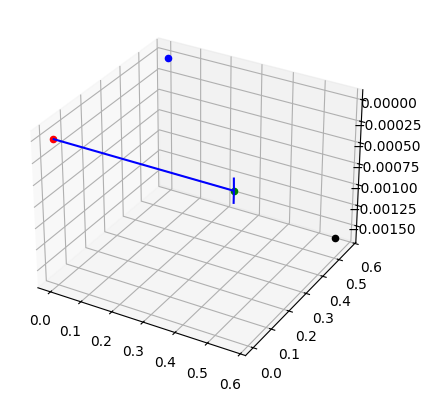

In [17]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')

points = np.array(aruco_t)

aruco_0 = points[0] - points[0]
aruco_1 = points[1] - points[0]
aruco_2 = points[2] - points[0]
aruco_3 = points[3] - points[0]

gamma = np.arctan2(-aruco_1[1], aruco_1[0])

Rz = np.array([[np.cos(gamma), -np.sin(gamma), 0],
               [np.sin(gamma), np.cos(gamma), 0],
               [0, 0, 1]])

aruco_1 = Rz @ aruco_1
aruco_2 = Rz @ aruco_2
aruco_3 = Rz @ aruco_3

beta = np.arctan2(aruco_1[2], aruco_1[0])
Ry = np.array([[np.cos(beta), 0, np.sin(beta)],
               [0, 1, 0],
               [-np.sin(beta), 0, np.cos(beta)]])

aruco_1 = Ry @ aruco_1
aruco_2 = Ry @ aruco_2
aruco_3 = Ry @ aruco_3

alpha = np.arctan2(-aruco_2[2], aruco_2[1])
Rx = np.array([[1, 0, 0],
               [0, np.cos(alpha), -np.sin(alpha)],
               [0, np.sin(alpha), np.cos(alpha)]])

aruco_1 = Rx @ aruco_1
aruco_2 = Rx @ aruco_2
aruco_3 = Rx @ aruco_3

print(np.rad2deg(alpha))
print(np.rad2deg(beta))
print(np.rad2deg(gamma))

world_to_aruco_R = (Rx @ Ry @ Rz).T

# aruco_1 = world_to_aruco_R @ aruco_1
# aruco_2 = world_to_aruco_R @ aruco_2
# aruco_3 = world_to_aruco_R @ aruco_3

print(aruco_2)
print(aruco_1)

ax.scatter(aruco_0[0], aruco_0[1], aruco_0[2], c='r')
ax.scatter(aruco_1[0], aruco_1[1], aruco_1[2], c='g')
ax.scatter(aruco_2[0], aruco_2[1], aruco_2[2], c='b')
ax.scatter(aruco_3[0], aruco_3[1], aruco_3[2], c='k')
ax.quiver(aruco_0[0], aruco_0[1], aruco_0[2], aruco_1[0] - aruco_0[0], aruco_1[1] - aruco_0[1], aruco_1[2] - aruco_0[2], colors='b', arrow_length_ratio=0.001)

# ax.set_xlim3d(-0.1, 1.0)
# ax.set_ylim3d(-0.1, 1.0)
# ax.set_zlim3d(-0.1, 0.1)

print(world_to_aruco_R)

plt.autoscale(False)
plt.show()

In [18]:
camera_path_before = []

# world_to_aruco_t = world_to_aruco_t[0][..., None]

world_to_aruco_t = None

# Calculate mean of aruco positions after rotation
world_to_aruco_ts = []
for trans_mat, trans, idx in arucos_before:
    temp = deepcopy(trans_mat)
    temp[:3, 3:] = temp[:3, 3:] / best_scale_before
    marker_pose = temp @ trans
    if idx == 0:
        marker_pose[:3, 3:] = world_to_aruco_R.T @ marker_pose[:3, 3:]
        world_to_aruco_ts.append(deepcopy(marker_pose[:3, 3:]))

world_to_aruco_ts = np.array(world_to_aruco_ts)
world_to_aruco_ts = reject_outliers_iqr(world_to_aruco_ts[:, :, 0])
world_to_aruco_t = np.mean(world_to_aruco_ts, axis=0)[..., None]

print(world_to_aruco_t)

for trans_mat, trans, idx in arucos_before:
    temp = deepcopy(trans_mat)
    temp[:3, 3:] = temp[:3, 3:] / best_scale_before
    marker_pose = temp @ trans

    marker_pose[:3, 3:] = world_to_aruco_R.T @ marker_pose[:3, 3:]
    marker_pose[:3, 3:] = marker_pose[:3, 3:] - world_to_aruco_t

    aruco_dict_before[idx].append(marker_pose)

    if idx == 0:
        temp[:3, 3:] = (world_to_aruco_R.T @ temp[:3, 3:]) - world_to_aruco_t
        camera_path_before.append(temp)

    i += 1

# Convert transform.json file to meters
for frame in transforms_before["frames"]:
    transform_matrix = np.array(frame["transform_matrix"])
    # Move frames from camera space to aruco id 0 space
    transform_matrix[:3, :3] = world_to_aruco_R.T @ transform_matrix[:3, :3]
    transform_matrix[:3, 3:] = transform_matrix[:3, 3:] / best_scale_before
    transform_matrix[:3, 3:] = (world_to_aruco_R.T @ transform_matrix[:3, 3:]) - world_to_aruco_t
    frame["transform_matrix"] = transform_matrix.tolist()

# with open(path_before / 'transforms.json', 'w') as file:
#     json.dump(transforms_before, file, indent=4)

[[-0.08317406]
 [-0.18707729]
 [-0.14535384]]


In [19]:
# Apply best scale and create aruco dictionary
aruco_dict_after = {}
for i in range(100):
    aruco_dict_after[i] = []

camera_path_after = []
i = 0

world_to_aruco_R = None
world_to_aruco_t = None

# Setup pose of 0 aruco marker as world center
for trans_mat, trans, idx in arucos_after:
    temp = deepcopy(trans_mat)
    temp[:3, 3:] = temp[:3, 3:] / best_scale_after
    marker_pose = temp @ trans
    if idx == 0:
        world_to_aruco_R = deepcopy(marker_pose[:3, :3])
        marker_pose[:3, 3:] = world_to_aruco_R.T @ marker_pose[:3, 3:]
        world_to_aruco_t = deepcopy(marker_pose[:3, 3:])
        break

for trans_mat, trans, idx in arucos_after:
    temp = deepcopy(trans_mat)
    temp[:3, 3:] = temp[:3, 3:] / best_scale_after
    marker_pose = temp @ trans
    marker_pose[:3, 3:] = world_to_aruco_R.T @ marker_pose[:3, 3:]
    marker_pose[:3, 3:] = marker_pose[:3, 3:] - world_to_aruco_t
    aruco_dict_after[idx].append(marker_pose)

    if idx == 0:
        temp[:3, 3:] = (world_to_aruco_R.T @ temp[:3, 3:]) - world_to_aruco_t
        camera_path_after.append(temp)

    i += 1

# Convert transform.json file to meters
for frame in transforms_after["frames"]:
    transform_matrix = np.array(frame["transform_matrix"])
    transform_matrix[:3, :3] = world_to_aruco_R.T @ transform_matrix[:3, :3]
    transform_matrix[:3, 3:] = transform_matrix[:3, 3:] / best_scale_after
    transform_matrix[:3, 3:] = (world_to_aruco_R.T @ transform_matrix[:3, 3:]) - world_to_aruco_t
    frame["transform_matrix"] = transform_matrix.tolist()

# with open(path_after / 'transforms.json', 'w') as file:
#     json.dump(transforms_after, file, indent=4)

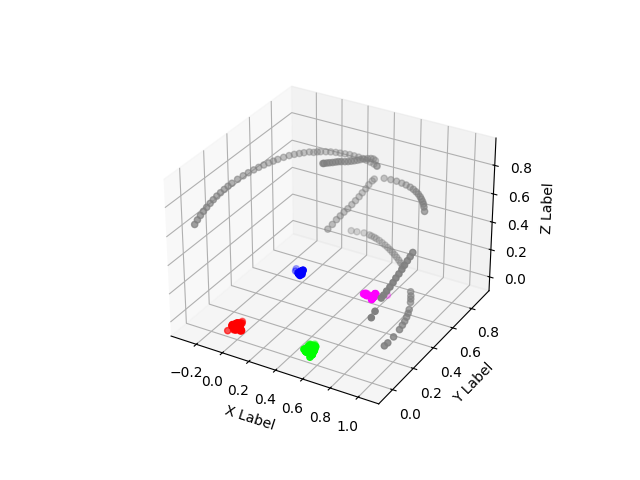

In [20]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt

fig = plt.figure()
ax = fig.add_subplot(projection='3d')

marker_poses_0 = np.array(aruco_dict_before[0])
marker_poses_1 = np.array(aruco_dict_before[1])
marker_poses_2 = np.array(aruco_dict_before[2])
marker_poses_3 = np.array(aruco_dict_before[3])
camera_path = np.array(camera_path_before)

start = 0
num = -1

ax.scatter(marker_poses_0[start:num, 0, 3], marker_poses_0[start:num, 1, 3], marker_poses_0[start:num, 2, 3], c=[(1, 0, 0, 1) for i in range(len(marker_poses_0[start:num, 2, 3]))])
ax.scatter(marker_poses_1[start:num, 0, 3], marker_poses_1[start:num, 1, 3], marker_poses_1[start:num, 2, 3], c=[(0, 1, 0, 1) for i in range(len(marker_poses_1[start:num, 2, 3]))])
ax.scatter(marker_poses_2[start:num, 0, 3], marker_poses_2[start:num, 1, 3], marker_poses_2[start:num, 2, 3], c=[(0, 0, 1, 1) for i in range(len(marker_poses_2[start:num, 2, 3]))])
ax.scatter(marker_poses_3[start:num, 0, 3], marker_poses_3[start:num, 1, 3], marker_poses_3[start:num, 2, 3], c=[(1, 0, 1, 1) for i in range(len(marker_poses_3[start:num, 2, 3]))])
ax.scatter(camera_path[:, 0, 3], camera_path[:, 1, 3], camera_path[:, 2, 3], c=[(0.5, 0.5, 0.5, 1) for i in range(len(camera_path))])

marker_poses_0 = np.array(aruco_dict_after[0])
marker_poses_1 = np.array(aruco_dict_after[1])
marker_poses_2 = np.array(aruco_dict_after[2])
marker_poses_3 = np.array(aruco_dict_after[3])
camera_path = np.array(camera_path_after)

# start = 0
# num = -1

# ax.scatter(marker_poses_0[start:num, 0, 3], marker_poses_0[start:num, 1, 3], marker_poses_0[start:num, 2, 3], c=[(1, 0, 0, 0.5) for i in range(len(marker_poses_0[start:num, 2, 3]))])
# ax.scatter(marker_poses_1[start:num, 0, 3], marker_poses_1[start:num, 1, 3], marker_poses_1[start:num, 2, 3], c=[(0, 1, 0, 0.5) for i in range(len(marker_poses_1[start:num, 2, 3]))])
# ax.scatter(marker_poses_2[start:num, 0, 3], marker_poses_2[start:num, 1, 3], marker_poses_2[start:num, 2, 3], c=[(0, 0, 1, 0.5) for i in range(len(marker_poses_2[start:num, 2, 3]))])
# ax.scatter(marker_poses_3[start:num, 0, 3], marker_poses_3[start:num, 1, 3], marker_poses_3[start:num, 2, 3], c=[(1, 0, 1, 0.5) for i in range(len(marker_poses_3[start:num, 2, 3]))])
# ax.scatter(camera_path[:, 0, 3], camera_path[:, 1, 3], camera_path[:, 2, 3], c=[(0.5, 0.5, 0.5, 0.5) for i in range(len(camera_path))])

# print(np.sum(np.diff(marker_poses_2[:, :3, 3], axis=0), axis=0))

ax.set_xlabel('X Label')
ax.set_ylabel('Y Label')
ax.set_zlabel('Z Label')

# ax.set_xlim(-1, 1)
# ax.set_ylim(-1, 1)
# ax.set_zlim(-1, 1)

plt.autoscale(False)
plt.show()

[-0.29820444  0.72145353  0.60701075]


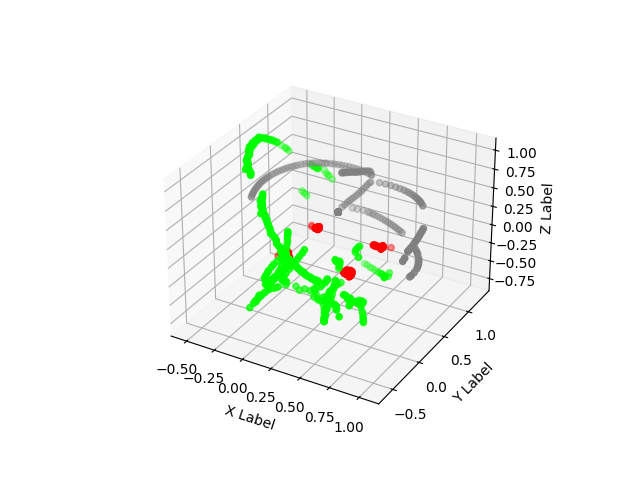

In [21]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt

fig = plt.figure()
ax = fig.add_subplot(projection='3d')

marker_poses_0 = np.array(aruco_dict_before[0])
marker_poses_1 = np.array(aruco_dict_before[1])
marker_poses_2 = np.array(aruco_dict_before[2])
marker_poses_3 = np.array(aruco_dict_before[3])
camera_path = np.array(camera_path_before)

start = 0
num = -1

ax.scatter(marker_poses_0[start:num, 0, 3], marker_poses_0[start:num, 1, 3], marker_poses_0[start:num, 2, 3], c=[(1, 0, 0, 1) for i in range(len(marker_poses_0[start:num, 2, 3]))])
ax.scatter(marker_poses_1[start:num, 0, 3], marker_poses_1[start:num, 1, 3], marker_poses_1[start:num, 2, 3], c=[(1, 0, 0, 1) for i in range(len(marker_poses_1[start:num, 2, 3]))])
ax.scatter(marker_poses_2[start:num, 0, 3], marker_poses_2[start:num, 1, 3], marker_poses_2[start:num, 2, 3], c=[(1, 0, 0, 1) for i in range(len(marker_poses_2[start:num, 2, 3]))])
ax.scatter(marker_poses_3[start:num, 0, 3], marker_poses_3[start:num, 1, 3], marker_poses_3[start:num, 2, 3], c=[(1, 0, 0, 1) for i in range(len(marker_poses_3[start:num, 2, 3]))])
ax.scatter(camera_path[:, 0, 3], camera_path[:, 1, 3], camera_path[:, 2, 3], c=[(0.5, 0.5, 0.5, 1) for i in range(len(camera_path))])

marker_poses_0 = np.array(aruco_dict_after[0])
marker_poses_1 = np.array(aruco_dict_after[1])
marker_poses_2 = np.array(aruco_dict_after[2])
marker_poses_3 = np.array(aruco_dict_after[3])
camera_path = np.array(camera_path_after)

start = 0
num = -1

ax.scatter(marker_poses_0[start:num, 0, 3], marker_poses_0[start:num, 1, 3], marker_poses_0[start:num, 2, 3], c=[(0, 1, 0, 1) for i in range(len(marker_poses_0[start:num, 2, 3]))])
ax.scatter(marker_poses_1[start:num, 0, 3], marker_poses_1[start:num, 1, 3], marker_poses_1[start:num, 2, 3], c=[(0, 1, 0, 1) for i in range(len(marker_poses_1[start:num, 2, 3]))])
ax.scatter(marker_poses_2[start:num, 0, 3], marker_poses_2[start:num, 1, 3], marker_poses_2[start:num, 2, 3], c=[(0, 1, 0, 1) for i in range(len(marker_poses_2[start:num, 2, 3]))])
ax.scatter(marker_poses_3[start:num, 0, 3], marker_poses_3[start:num, 1, 3], marker_poses_3[start:num, 2, 3], c=[(0, 1, 0, 1) for i in range(len(marker_poses_3[start:num, 2, 3]))])
ax.scatter(camera_path[:, 0, 3], camera_path[:, 1, 3], camera_path[:, 2, 3], c=[(0.5, 0.5, 0.5, 0.5) for i in range(len(camera_path))])

print(np.sum(np.diff(marker_poses_2[:, :3, 3], axis=0), axis=0))

ax.set_xlabel('X Label')
ax.set_ylabel('Y Label')
ax.set_zlabel('Z Label')

# ax.set_xlim(-1, 1)
# ax.set_ylim(-1, 1)
# ax.set_zlim(-1, 1)

plt.autoscale(False)
plt.show()